# Mouse Serum aggregation

Read the source protocol CSVs for one condition and write its compact, deduplicated union.

In [1]:
CONDITION="mouse_serum"
WRITE_EXPORTS=True
NOTEBOOK_ID="aggregation_mouse_serum"
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "src/pep_compass").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.protocols.half_life.filtering import load_half_life_data, prepare_protocol, export_protocol
from proteolysis_data_manager.integration.half_life.schema import CLEAN_COLUMNS, source_mask, row_key, typed
from proteolysis_data_manager.analysis.half_life.visualization import (formatted_table, duration_summary, plot_duration_distributions,
    plot_acceptance_conditions, plot_before_after, readable_time_axis, time_bins, DURATION_COLORS, DURATION_LABELS)
DATA_ROOT = ROOT / "data/half_time_datasets"
SERIES = ROOT / "assets/experiments/analysis/09_26/20_serum_proteolysis_calibration_max/notebooks/0_data_analysis_half_life"
RESULTS = SERIES.parents[1] / "results/0_data_analysis_half_life" / CONDITION / NOTEBOOK_ID
if WRITE_EXPORTS: RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi":110, "axes.spines.top":False, "axes.spines.right":False, "axes.grid":True, "grid.alpha":.12})
def table(frame):
    if len(frame)>30: display(HTML(f"<p>Preview: 30 of {len(frame)} rows.</p>"))
    display(HTML(formatted_table(frame, limit=30)))
def figure(fig, name):
    if WRITE_EXPORTS: fig.savefig(RESULTS / name, bbox_inches="tight")
    plt.show(); plt.close(fig)
def counts(frame):
    point=frame.half_life_seconds.notna()
    return {"observations":len(frame), "sequences":frame.sequence.nunique(), "numeric":int(point.sum()),
            "class_only":int((~point & frame.half_life_class.notna()).sum()),
            "unresolved":int((~point & frame.half_life_class.isna()).sum())}

from proteolysis_data_manager.integration.half_life.aggregation import aggregate_environment, source_accounting
SOURCES=["peplife2","plifepred","dramp","pepmsnd","cavaco"]


## Inputs and verified measurement identity

Central manifests verify input CSVs and their shared normalization/protocol policy. A shared source reference plus identical scientific fields establishes a repeated normalized measurement. Equal sequences or equal half-lives alone do not. Missing fields were already enriched during normalization, and the complete source/ID lists survive final aggregation.

No wide provenance columns or report files are added. Conflicting measurements remain separate; their explanations are in `normalized/remarks_<source>.md`.

In [2]:
if not WRITE_EXPORTS:
    raise RuntimeError("Template export disabled. Copy into a condition folder and enable WRITE_EXPORTS.")
before, after, lineage, possible, manifest = aggregate_environment(DATA_ROOT, CONDITION, SOURCES)
table(pd.DataFrame(manifest["inputs"]))
table(pd.DataFrame([{"condition":CONDITION,"source_input_rows":len(before),"final_measurements":len(after),"repeated_input_rows_merged":len(before)-len(after),**counts(after),"reported_ci95":int(after.ci_level.eq(.95).sum()),"unconfirmed_coincident_points":len(possible)}]))

source,csv,sha256,source_rows
peplife2,processed/mouse_serum/sources/peplife2.csv,9996d4427ab190691fe4932ffd27be6e4f093154562591f29842f27767bbb9cf,120
plifepred,processed/mouse_serum/sources/plifepred.csv,bc47759d9da60cc3deea627da32204edc79faf16be4df3a63378b3234232afb1,4
dramp,processed/mouse_serum/sources/dramp.csv,b39517b0258e9a3f155c4ebf118e0596d59db411d7597c180568f80c0f645b11,0
pepmsnd,processed/mouse_serum/sources/pepmsnd.csv,82d536e412b0ef55954c900521ffc61922f75d3d73e5a8a6ac2bb226e1b63943,24
cavaco,processed/mouse_serum/sources/cavaco.csv,b39517b0258e9a3f155c4ebf118e0596d59db411d7597c180568f80c0f645b11,0


condition,source_input_rows,final_measurements,repeated_input_rows_merged,observations,sequences,numeric,class_only,unresolved,reported_ci95,unconfirmed_coincident_points
mouse_serum,148,146,2,146,65,115,5,26,0,50


## Source coverage, label availability and PEPlife2 overlap

Raw source representations and normalized measurements have different denominators: normalization merges verified repeated source rows. The next reduction selects species/matrix and the explicit assay mode, then applies pH/temperature gates. Tables account for each reduction.

Every retained row belongs to one label group: numerical, class-only, or unresolved. Missing half-life does not remove it. Shared sequences and verified shared measurements with PEPlife2 are reported separately; sequence overlap is not deduplication evidence.

coverage


source,raw_source_representations,normalized_measurements,condition_records,selected_assay_mode,other_known_mode,unknown_assay_mode,outside_ph_temperature,exported_source_records
peplife2,4500,4366,272,120,150,2,0,120
plifepred,424,261,17,4,13,0,0,4
dramp,111,111,33,0,15,18,0,0
pepmsnd,635,635,51,24,27,0,0,24
cavaco,16,16,0,0,0,0,0,0


label_types


source,exported_records,numeric,class_only,unresolved,without_numeric_half_life
peplife2,120,89,5,26,31
plifepred,4,4,0,0,0
dramp,0,0,0,0,0
pepmsnd,24,24,0,0,0
cavaco,0,0,0,0,0


peplife2_overlap


source,comparison,shared_sequences,shared_sequence_records,verified_same_measurements,new_sequences
peplife2,reference,49,120,None,0
plifepred,against PEPlife2,3,4,2,0
dramp,against PEPlife2,0,0,0,0
pepmsnd,against PEPlife2,1,2,0,16
cavaco,against PEPlife2,0,0,0,0


source,parameter,cavaco,dramp,peplife2,pepmsnd,plifepred
,ci_level,0,0,120,24,4
,ci_lower_seconds,0,0,120,24,4
,ci_upper_seconds,0,0,120,24,4
,half_life_class,0,0,26,0,0
,half_life_seconds,0,0,31,0,0
,matrix_fraction,0,0,113,24,2
,peptide_concentration_um,0,0,115,24,4
,ph,0,0,120,24,4
,replicate_count,0,0,120,24,4
,sd_seconds,0,0,120,24,4


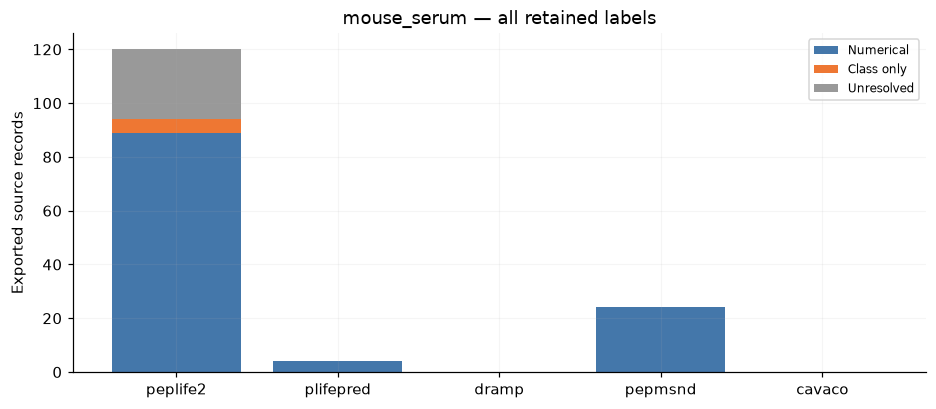

In [3]:
inventory=load_half_life_data(DATA_ROOT)
accounting=source_accounting(DATA_ROOT,inventory,before,after,manifest["configuration"],SOURCES)
for name in ["coverage","label_types","peplife2_overlap"]:
    print(name); table(accounting[name])
table(accounting["missingness"].pivot(index="parameter",columns="source",values="missing").reset_index())
labels=accounting["label_types"].set_index("source")
fig,ax=plt.subplots(figsize=(10,4)); bottom=pd.Series(0,index=labels.index)
for field,color,label in [("numeric","#4477AA","Numerical"),("class_only","#EE7733","Class only"),("unresolved","#999999","Unresolved")]:
    ax.bar(labels.index,labels[field],bottom=bottom,color=color,label=label);bottom+=labels[field]
ax.set(ylabel="Exported source records",title=CONDITION+" — all retained labels");ax.legend(fontsize=8)
figure(fig,"source_label_availability.png")
for _,r in accounting["label_types"].iterrows():
    assert r.numeric+r.class_only+r.unresolved==r.exported_records
for _,r in accounting["coverage"].iterrows():
    assert r.condition_records==r.selected_assay_mode+r.other_known_mode+r.unknown_assay_mode
    assert r.selected_assay_mode==r.outside_ph_temperature+r.exported_source_records

## Duration classes, distributions and missingness

**short** <30 min (blue); **medium** 30 min–6 h inclusive (orange); **long** >6 h (green); unresolved (gray). All numerical and class-only observations enter class counts. Numerical histograms use reported points or the explicitly documented CI-midpoint exception only.

Before/after counts here describe merging source copies of shared observations, not filtering out class-only data.

duration_class,time_interval,all_assigned_records,exact_point_records,bounded_or_non_numeric_records,stage
unresolved,no unique interval,26,0,26,Source CSV inputs
short,<30 min,52,52,0,Source CSV inputs
medium,30 min–6 h,55,55,0,Source CSV inputs
long,>6 h,15,10,5,Source CSV inputs
unresolved,no unique interval,26,0,26,Deduplicated union
short,<30 min,50,50,0,Deduplicated union
medium,30 min–6 h,55,55,0,Deduplicated union
long,>6 h,15,10,5,Deduplicated union


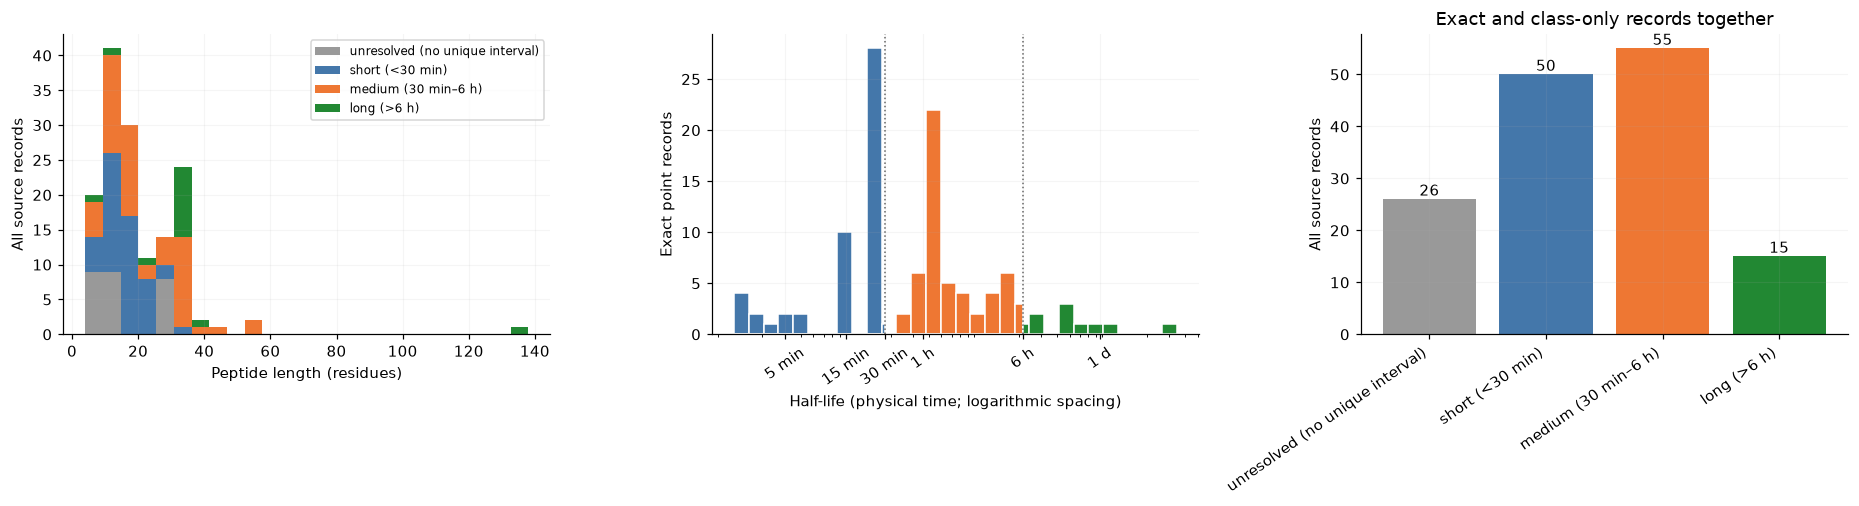

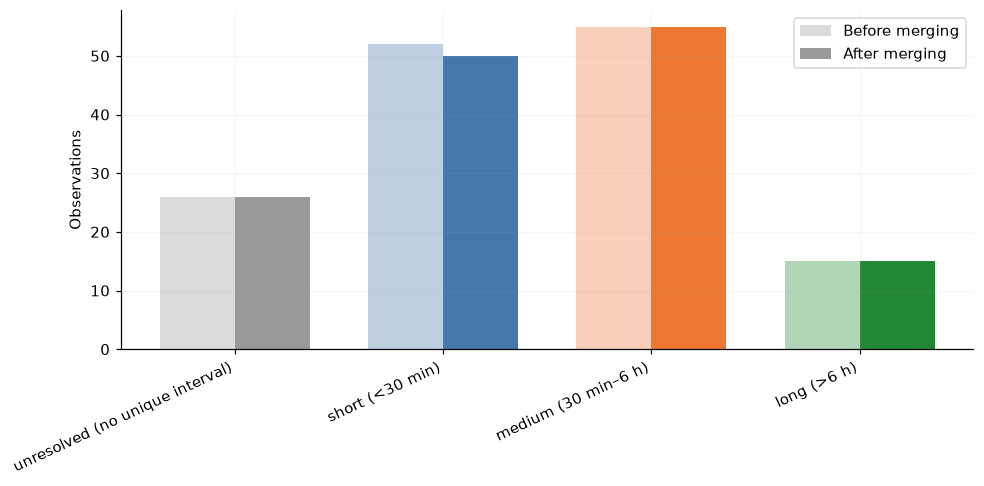

field,missing,denominator
sequence,0,146
sequence_length,0,146
chirality,24,146
topology,0,146
n_terminal_modification,0,146
c_terminal_modification,0,146
other_modifications,0,146
species,0,146
matrix,0,146
matrix_fraction,137,146


normalized_row_key,source,id
5b4e76111c08572d089bc9c2bd391adfebb14dacc658616d4d1afebae0e6dfb1,peplife2,all:1113
5b4e76111c08572d089bc9c2bd391adfebb14dacc658616d4d1afebae0e6dfb1,peplife2,all:1121
5b4e76111c08572d089bc9c2bd391adfebb14dacc658616d4d1afebae0e6dfb1,peplife2,all:1129
5b4e76111c08572d089bc9c2bd391adfebb14dacc658616d4d1afebae0e6dfb1,peplife2,all:1137
5b4e76111c08572d089bc9c2bd391adfebb14dacc658616d4d1afebae0e6dfb1,peplife2,all:1145
5b4e76111c08572d089bc9c2bd391adfebb14dacc658616d4d1afebae0e6dfb1,peplife2,all:1153
5b4e76111c08572d089bc9c2bd391adfebb14dacc658616d4d1afebae0e6dfb1,peplife2,all:1161
5b4e76111c08572d089bc9c2bd391adfebb14dacc658616d4d1afebae0e6dfb1,peplife2,all:1169
5b4e76111c08572d089bc9c2bd391adfebb14dacc658616d4d1afebae0e6dfb1,plifepred,mixed:1169
5b4e76111c08572d089bc9c2bd391adfebb14dacc658616d4d1afebae0e6dfb1,plifepred,natural:1169


source,source_record_id,sequence,sequence_length,chirality,topology,n_terminal_modification,c_terminal_modification,other_modifications,species,matrix,matrix_fraction,temperature_c,ph,peptide_concentration_um,half_life_seconds,sd_seconds,ci_lower_seconds,ci_upper_seconds,ci_level,replicate_count,half_life_class,in_vivo_in_vitro
"[peplife2, plifepred]","[{'id': 'all:1113', 'source': 'peplife2'}, {'id': 'all:1121', 'source': 'peplife2'}, {'id': 'all:1129', 'source': 'peplife2'}, {'id': 'all:1137', 'source': 'peplife2'}, {'id': 'all:1145', 'source': 'peplife2'}, {'id': 'all:1153', 'source': 'peplife2'}, {'id': 'all:1161', 'source': 'peplife2'}, {'id': 'all:1169', 'source': 'peplife2'}, {'id': 'mixed:1169', 'source': 'plifepred'}, {'id': 'natural:1169', 'source': 'plifepred'}]",KKVVFKVKFK,10,l,linear,free,free,free,mouse,serum,<NA>,<NA>,<NA>,<NA>,360,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:1120', 'source': 'peplife2'}]",KKVVFKVKFK,10,mix,linear,free,free,free,mouse,serum,<NA>,<NA>,<NA>,<NA>,1320,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:1128', 'source': 'peplife2'}]",KKVVFKVKFK,10,mix,linear,free,free,free,mouse,serum,<NA>,<NA>,<NA>,<NA>,1320,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:1136', 'source': 'peplife2'}]",KKVVFKVKFK,10,mix,linear,free,free,free,mouse,serum,<NA>,<NA>,<NA>,<NA>,1320,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:1144', 'source': 'peplife2'}]",KKVVFKVKFK,10,mix,linear,free,free,free,mouse,serum,<NA>,<NA>,<NA>,<NA>,1320,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:1152', 'source': 'peplife2'}]",KKVVFKVKFK,10,mix,linear,free,free,free,mouse,serum,<NA>,<NA>,<NA>,<NA>,1320,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:1160', 'source': 'peplife2'}]",KKVVFKVKFK,10,mix,linear,free,free,free,mouse,serum,<NA>,<NA>,<NA>,<NA>,1320,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:1168', 'source': 'peplife2'}]",KKVVFKVKFK,10,mix,linear,free,free,free,mouse,serum,<NA>,<NA>,<NA>,<NA>,1320,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
"[peplife2, plifepred]","[{'id': 'all:1176', 'source': 'peplife2'}, {'id': 'mixed:1176', 'source': 'plifepred'}]",KKVVFKVKFK,10,mix,linear,free,free,free,mouse,serum,<NA>,<NA>,<NA>,<NA>,1320,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro
[peplife2],"[{'id': 'all:1114', 'source': 'peplife2'}]",KÎ¨[CH2NH]KVVFKVKFK,19,l,linear,free,free,reduced amide bonds î¨(ch2nh),mouse,serum,<NA>,<NA>,<NA>,<NA>,840,<NA>,<NA>,<NA>,<NA>,<NA>,short,in vitro


In [4]:
table(pd.concat([duration_summary(before).assign(stage="Source CSV inputs"),duration_summary(after).assign(stage="Deduplicated union")],ignore_index=True))
figure(plot_duration_distributions(after),"final_distributions.png")
summary_before=duration_summary(before);summary_after=duration_summary(after);x=np.arange(len(summary_after))
fig,ax=plt.subplots(figsize=(10,4))
colors=[DURATION_COLORS[c] for c in summary_after.duration_class]
ax.bar(x-.18,summary_before.all_assigned_records,width=.36,color=colors,alpha=.35,label="Before merging")
ax.bar(x+.18,summary_after.all_assigned_records,width=.36,color=colors,label="After merging")
ax.set_xticks(x,[DURATION_LABELS[c] for c in summary_after.duration_class],rotation=25,ha="right");ax.set(ylabel="Observations");ax.legend()
figure(fig,"before_after_classes.png")
table(pd.DataFrame([{"field":f,"missing":int(after[f].isna().sum()),"denominator":len(after)} for f in CLEAN_COLUMNS if f not in ["source","source_record_id"]]))
table(lineage);table(possible)
assert not after.apply(row_key,axis=1).duplicated().any()

## Final common CSV

The result uses the same 23 fields as normalization and source protocols. Select `half_life_seconds.notna()` for numerical analysis; select `half_life_seconds.isna() & half_life_class.notna()` for class-only validation. Both can use the duration class. Unresolved labels remain present with null values. Missing SD and CI stay null.

`source` is a list of all contributing bases; `source_record_id` is the full list of source-qualified references. In CSV these two fields are JSON; the library reader decodes them.

TODO (later analysis): estimate validation tolerances separately without changing reported CI.

In [5]:
table(pd.DataFrame({"column":CLEAN_COLUMNS}))
print("Final CSV:",DATA_ROOT/"processed"/CONDITION/(CONDITION+".csv"))

column
source
source_record_id
sequence
sequence_length
chirality
topology
n_terminal_modification
c_terminal_modification
other_modifications
species


Final CSV: /Users/max/Documents/repositories/pep-compass/data/half_time_datasets/processed/mouse_serum/mouse_serum.csv
